# Synthetic data feasibility: SEER breast cancer

**Decision:** assess whether minority-class augmentation is defensible; no synthetic data are created and no classifier is trained. Run all cells in order. The final report is computed from the loaded data, not prewritten conclusions.

**Scope:** descriptive whole-dataset exploration only; repeat all decisions on training data after defining a leakage-safe split. Test data must not guide method selection. Associations are not causal, and synthetic records are not independent clinical evidence.


## 1. Configuration and imports

Update paths and overrides as needed. The default five-year definition follows the project protocol: death before 60 months = 1; follow-up of at least 60 months = 0; alive with shorter follow-up is censored and excluded. This is a binary endpoint, not a survival model. Check original coding and follow-up documentation before clinical use.

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import mutual_info_score
from IPython.display import display, Markdown

DATA_PATH = Path(r'C:\Users\Tommaso\Code\progetto\Copia di SEER Breast Cancer Dataset .csv')
OUTPUT_DIR = Path('synthetic_feasibility_output')
SAVE_OUTPUTS = False  # Set True to save figures and the Markdown report locally.
TARGET_MODE = 'five_year'  # 'five_year' or 'column'
TARGET_COLUMN = 'Status'   # only used when TARGET_MODE == 'column'
SURVIVAL_COLUMN = 'Survival Months'
STATUS_COLUMN = 'Status'
POSITIVE_STATUS = ['dead', 'deceased']
ALIVE_STATUS = ['alive']
FEATURE_COLUMNS = None  # None = all eligible columns; set an explicit list to select eight predictors
EXCLUDE_COLUMNS = []
NUMERICAL_OVERRIDE = []
CATEGORICAL_OVERRIDE = []
ORDINAL_ORDERS = {}  # e.g. {'T Stage': ['T1', 'T2', 'T3', 'T4']}; supply only verified clinical order
DEMOGRAPHIC_COLUMNS = None  # None detects age, race, ethnicity, sex, etc.
AGE_BINS = [0, 40, 50, 60, 70, 80, 120]
MIN_GROUP_N = 30
MIN_MINORITY_GROUP_N = 20
RANDOM_SEED = 42
MAX_CATEGORIES = 20
np.random.seed(RANDOM_SEED)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.titleweight': 'bold'})
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def finish(fig, name):
    fig.tight_layout()
    if SAVE_OUTPUTS: fig.savefig(OUTPUT_DIR / (name + '.png'), bbox_inches='tight')
    plt.show()

def heading(text): display(Markdown(text))


Matplotlib is building the font cache; this may take a moment.


## 2. Load, audit and define the outcome

The source is never overwritten. Columns are stripped of surrounding spaces on a working copy. Blank strings and common missing markers are treated as missing. Death at or after 60 months meets the five-year endpoint; this is not equivalent to current vital status.

Input: C:\Users\Tommaso\Code\progetto\Copia di SEER Breast Cancer Dataset .csv | Shape: (4024, 16)


,Age,Race,Marital Status,Unnamed: 3,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),NaN,T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,NaN,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


,dtype,non_missing,unique
Age,int64,4024,40
Race,string,4024,3
Marital Status,string,4024,5
Unnamed: 3,float64,0,0
T Stage,string,4024,4
N Stage,string,4024,3
6th Stage,string,4024,5
Grade,string,4024,4
A Stage,string,4024,2
Tumor Size,int64,4024,110


All-missing columns: ['Unnamed: 3'] | Exact duplicate rows: 1
Alive with <60 months (censored): 754 | Invalid or unrecognized outcome: 0
Status values: {'Alive': 3408, 'Dead': 616}
Death before 60 months (1) vs survival to 60 months (0) | Included: 3270 | Counts: {'0': 2821, '1': 449} | Minority: 1 | Ratio: 6.28


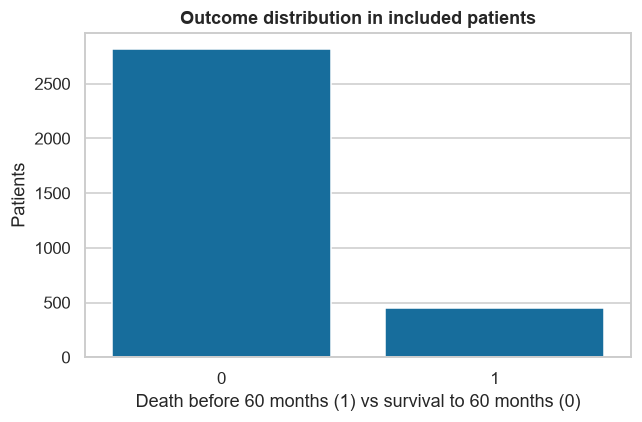

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Update DATA_PATH in the configuration: {DATA_PATH}')
raw = pd.read_csv(DATA_PATH)
df = raw.copy(deep=True)
df.columns = [str(c).strip() for c in df.columns]
if df.columns.duplicated().any():
    raise ValueError('Duplicate column names after whitespace normalization; resolve them in a copy of the file.')
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype('string').str.strip().replace({'': pd.NA, 'NA': pd.NA, 'N/A': pd.NA, 'nan': pd.NA, 'Unknown': pd.NA})
print('Input:', DATA_PATH.resolve(), '| Shape:', df.shape)
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'non_missing': df.notna().sum(), 'unique': df.nunique()}))
empty_cols = df.columns[df.isna().all()].tolist()
print('All-missing columns:', empty_cols, '| Exact duplicate rows:', int(df.duplicated().sum()))
if TARGET_MODE == 'five_year':
    missing_required = [c for c in [SURVIVAL_COLUMN, STATUS_COLUMN] if c not in df]
    if missing_required: raise ValueError(f'Five-year endpoint requires {missing_required}. Check configuration or use TARGET_MODE="column".')
    months = pd.to_numeric(df[SURVIVAL_COLUMN], errors='coerce')
    status = df[STATUS_COLUMN].astype('string').str.casefold()
    alive, dead = status.isin(ALIVE_STATUS), status.isin(POSITIVE_STATUS)
    valid = months.notna() & (months >= 0) & (alive | dead)
    y = pd.Series(pd.NA, index=df.index, dtype='Int64')
    y.loc[valid & (months >= 60)] = 0
    y.loc[valid & dead & (months < 60)] = 1
    censored = valid & alive & (months < 60)
    print('Alive with <60 months (censored):', int(censored.sum()), '| Invalid or unrecognized outcome:', int((~valid).sum()))
    print('Status values:', df[STATUS_COLUMN].value_counts(dropna=False).to_dict())
    if ((months < 0) | (months.isna() & df[SURVIVAL_COLUMN].notna())).any(): print('WARNING: invalid survival duration found.')
    outcome_name = 'Death before 60 months (1) vs survival to 60 months (0)'
elif TARGET_MODE == 'column':
    if TARGET_COLUMN not in df: raise ValueError(f'Target column {TARGET_COLUMN!r} not found')
    y = df[TARGET_COLUMN].copy()
    censored = pd.Series(False, index=df.index)
    outcome_name = f'Observed {TARGET_COLUMN}; five-year interpretation is NOT established'
else: raise ValueError('TARGET_MODE must be five_year or column')
analysis = df.loc[y.notna()].copy()
analysis['_target'] = y.loc[y.notna()].astype(str)
counts = analysis['_target'].value_counts()
if len(counts) != 2: raise ValueError(f'Expected exactly two observed classes; found {counts.to_dict()}')
minority, majority = counts.index[-1], counts.index[0]
print(outcome_name, '| Included:', len(analysis), '| Counts:', counts.to_dict(), '| Minority:', minority, '| Ratio:', round(counts.iloc[0]/counts.iloc[1], 2))
fig, ax = plt.subplots(figsize=(6,4)); sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set(title='Outcome distribution in included patients', xlabel=outcome_name, ylabel='Patients'); finish(fig, 'class_distribution')


### Candidate features, missingness and quality

Automatic types are heuristics, not clinical definitions. Numeric-looking low-cardinality fields are treated as categorical; ordinal variables remain categorical unless their full verified order is explicitly supplied. Audit attributes can remain available even if excluded from predictors.

In [3]:
leakage_patterns = re.compile(r'(survival|follow.?up|vital.?status|^status$|^label$|^_target$|^death|^outcome$|patient.?id|^id$)', re.I)
excluded = {c for c in df if leakage_patterns.search(c)} | set(EXCLUDE_COLUMNS) | set(empty_cols)
excluded |= {TARGET_COLUMN, SURVIVAL_COLUMN, STATUS_COLUMN}
available = [c for c in df if c not in excluded]
if FEATURE_COLUMNS is None: features = available
else:
    missing_features = [c for c in FEATURE_COLUMNS if c not in df]
    blocked = [c for c in FEATURE_COLUMNS if c in excluded]
    if missing_features or blocked: raise ValueError(f'Invalid feature selection; missing={missing_features}, excluded/leakage={blocked}')
    features = list(FEATURE_COLUMNS)
if not features: raise ValueError('No candidate predictors. Review configuration and column names.')
overlaps = (set(NUMERICAL_OVERRIDE) & set(CATEGORICAL_OVERRIDE)) | (set(NUMERICAL_OVERRIDE) & set(ORDINAL_ORDERS)) | (set(CATEGORICAL_OVERRIDE) & set(ORDINAL_ORDERS))
if overlaps: raise ValueError(f'Conflicting type overrides: {overlaps}')
numerical, categorical, ordinal = [], [], []
for c in features:
    if c in ORDINAL_ORDERS: ordinal.append(c)
    elif c in NUMERICAL_OVERRIDE: numerical.append(c)
    elif c in CATEGORICAL_OVERRIDE: categorical.append(c)
    elif pd.api.types.is_numeric_dtype(analysis[c]) and analysis[c].nunique() > 10: numerical.append(c)
    else: categorical.append(c)
for c in numerical:
    analysis[c] = pd.to_numeric(analysis[c], errors='coerce')
for c in ordinal:
    unknown = set(analysis[c].dropna().astype(str)) - set(map(str, ORDINAL_ORDERS[c]))
    if unknown: print(f'WARNING: {c} values missing from specified order: {unknown}')
print('Eligible predictors:', features, f'(n={len(features)}); excluded:', sorted(set(df.columns)-set(features)))
print('Numerical:', numerical, '| Categorical:', categorical, '| Ordinal:', ordinal)
quality = pd.DataFrame({'missing_n': analysis[features].isna().sum(), 'missing_pct': analysis[features].isna().mean()*100, 'unique': analysis[features].nunique()}).sort_values('missing_pct', ascending=False)
display(quality.round(2))
patterns = analysis[features].isna().apply(lambda r: ', '.join(r.index[r]) if r.any() else 'Complete', axis=1).value_counts().head(10)
display(patterns.rename('patients').to_frame())
for c in categorical + ordinal:
    vals = analysis[c].dropna().astype(str)
    variants = vals.groupby(vals.str.casefold().str.replace(r'\s+', ' ', regex=True)).nunique()
    if (variants > 1).any(): print(f'Possible inconsistent spellings in {c}:', variants[variants > 1].to_dict())
for c in numerical:
    s=analysis[c].dropna(); low=c.lower()
    bad = (s < 0) if any(x in low for x in ['age', 'size', 'node', 'count']) else pd.Series(False, index=s.index)
    if 'age' in low: bad |= s > 120
    if bad.any(): print(f'Potentially implausible {c}: {int(bad.sum())} rows; verify units and coding.')


Eligible predictors: ['Age', 'Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'Grade', 'A Stage', 'Tumor Size', 'Estrogen Status', 'Progesterone Status', 'Regional Node Examined', 'Reginol Node Positive'] (n=13); excluded: ['Status', 'Survival Months', 'Unnamed: 3']
Numerical: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive'] | Categorical: ['Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'Grade', 'A Stage', 'Estrogen Status', 'Progesterone Status'] | Ordinal: []


,missing_n,missing_pct,unique
Age,0,0.0,40
Race,0,0.0,3
Marital Status,0,0.0,5
T Stage,0,0.0,4
N Stage,0,0.0,3
6th Stage,0,0.0,5
Grade,0,0.0,4
A Stage,0,0.0,2
Tumor Size,0,0.0,106
Estrogen Status,0,0.0,2


,patients
Complete,3270


## 3. Minority distributions and class comparisons

IQR fences flag observations for review, not automatic removal. Skew, kurtosis and normality tests are descriptive and sensitive to sample size; a marginal Gaussian appearance does not establish joint normality. Mann–Whitney rank-biserial effect is directional (minority versus majority); chi-square Cramér’s V measures association, not clinical importance. Multiple comparisons are exploratory and unadjusted.

,feature,n,mean,median,std,variance,q05,q25,q75,q95,skew,excess_kurtosis,IQR_flags,normality_p,MW_p,rank_biserial
0,Age,449,55.116,56.0,9.606,92.268,38.0,48.0,63.0,68.6,-0.410,-0.740,0,0.0,0.003,0.087
1,Tumor Size,449,38.281,30.0,24.591,604.716,12.0,20.0,50.0,88.0,1.358,1.914,16,0.0,0.000,0.246
2,Regional Node Examined,449,15.350,14.0,8.830,77.965,3.0,9.0,20.0,30.0,1.016,2.050,8,0.0,0.050,0.058
3,Reginol Node Positive,449,7.454,5.0,7.523,56.592,1.0,2.0,11.0,23.6,1.561,2.472,18,0.0,0.000,0.328


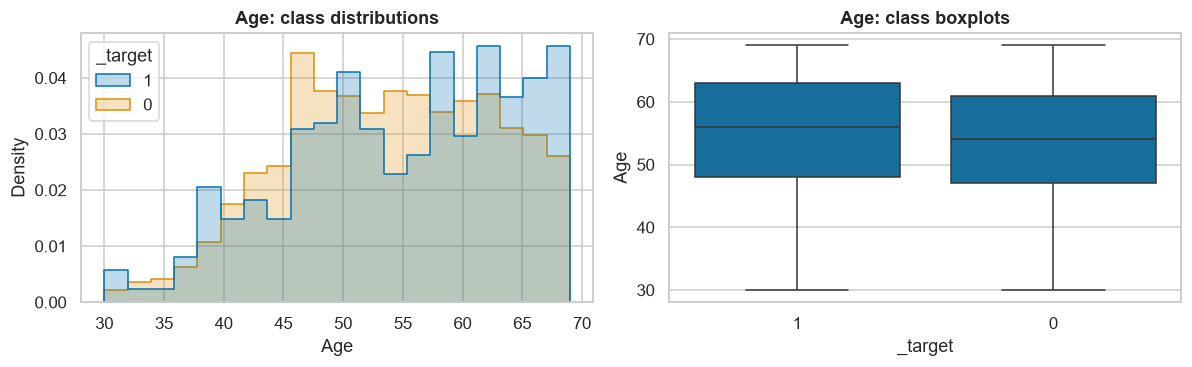

Age: 2 prominent KDE peak(s) at default bandwidth; visually check bandwidth and discreteness.


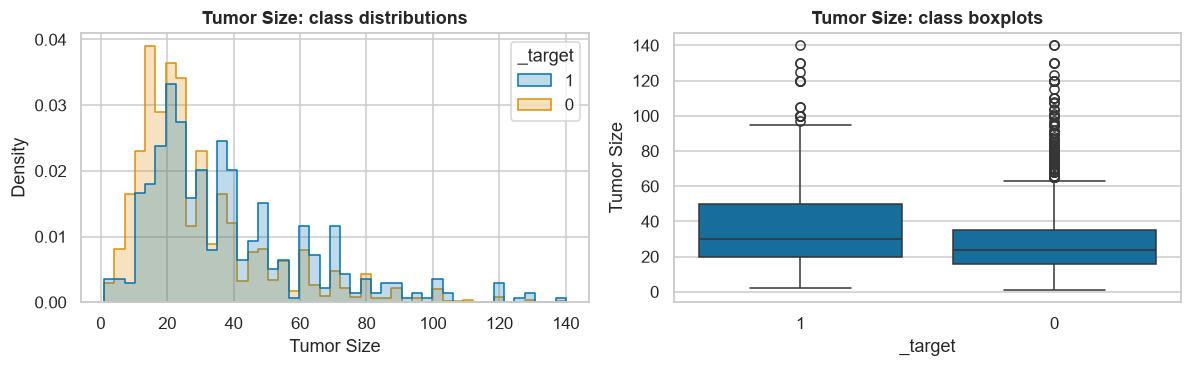

Tumor Size: 1 prominent KDE peak(s) at default bandwidth; visually check bandwidth and discreteness.


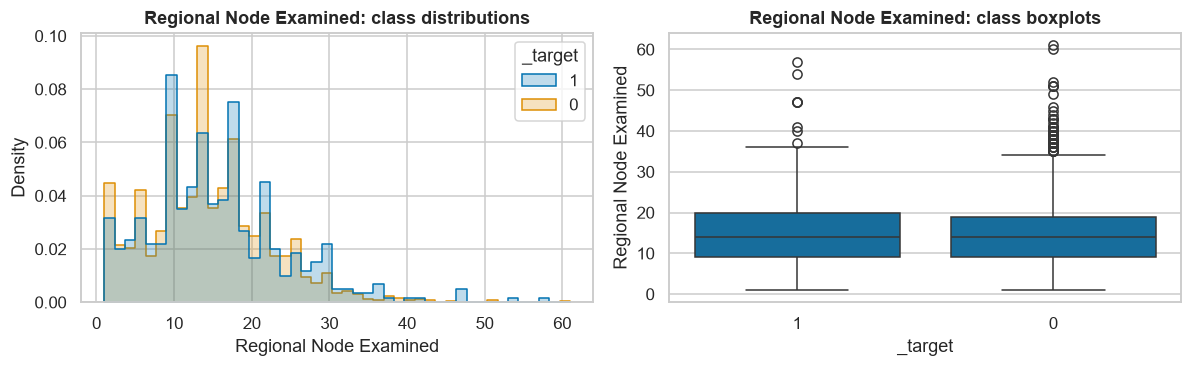

Regional Node Examined: 1 prominent KDE peak(s) at default bandwidth; visually check bandwidth and discreteness.


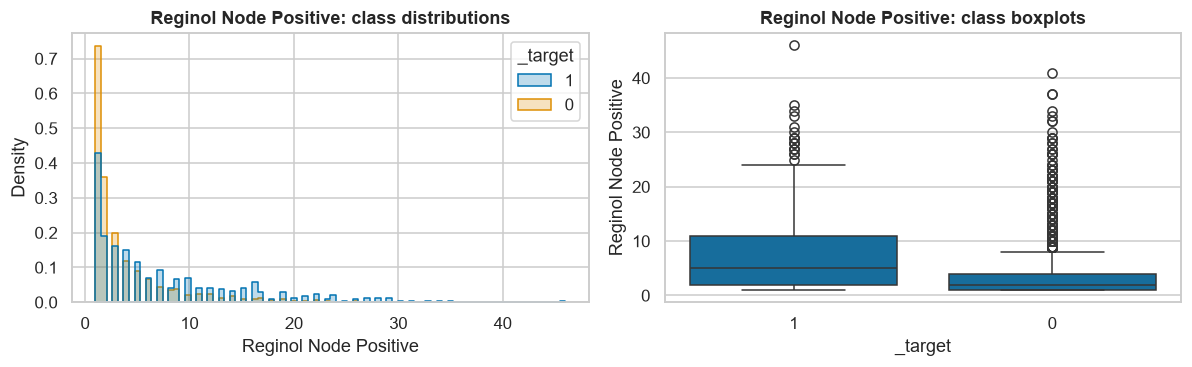

Reginol Node Positive: 1 prominent KDE peak(s) at default bandwidth; visually check bandwidth and discreteness.


In [4]:
minor = analysis[analysis['_target'] == minority]
major = analysis[analysis['_target'] == majority]
num_rows=[]
for c in numerical:
    x=minor[c].dropna(); z=major[c].dropna()
    if len(x)==0: continue
    q1,q3=x.quantile([.25,.75]); iqr=q3-q1
    out=((x<q1-1.5*iqr)|(x>q3+1.5*iqr)).sum() if iqr>0 else np.nan
    pnorm=stats.normaltest(x).pvalue if len(x)>=8 and x.nunique()>2 else np.nan
    if len(z) and x.nunique()+z.nunique()>2:
        u,p=stats.mannwhitneyu(x,z,alternative='two-sided'); effect=2*u/(len(x)*len(z))-1
    else: p=effect=np.nan
    num_rows.append({'feature':c,'n':len(x),'mean':x.mean(),'median':x.median(),'std':x.std(),'variance':x.var(),'q05':x.quantile(.05),'q25':q1,'q75':q3,'q95':x.quantile(.95),'skew':x.skew(),'excess_kurtosis':x.kurt(),'IQR_flags':out,'normality_p':pnorm,'MW_p':p,'rank_biserial':effect})
num_stats=pd.DataFrame(num_rows)
display(num_stats.round(3) if not num_stats.empty else pd.DataFrame({'note':['No eligible numerical features']}))
for c in numerical:
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    sns.histplot(data=analysis,x=c,hue='_target',stat='density',common_norm=False,element='step',ax=axes[0])
    sns.boxplot(data=analysis,x='_target',y=c,ax=axes[1],showfliers=True)
    axes[0].set_title(f'{c}: class distributions'); axes[1].set_title(f'{c}: class boxplots')
    finish(fig, 'numeric_'+re.sub(r'\W+','_',c))
    x=minor[c].dropna()
    if len(x)>=20 and x.nunique()>=10 and x.std()>0:
        # Sensitivity to bandwidth is reported; peaks are exploratory, not a formal multimodality test.
        grid=np.linspace(x.min(),x.max(),256); kde=stats.gaussian_kde(x); curve=kde(grid)
        peaks=np.where((curve[1:-1]>curve[:-2]) & (curve[1:-1]>curve[2:]) & (curve[1:-1]>.1*curve.max()))[0]
        print(f'{c}: {len(peaks)} prominent KDE peak(s) at default bandwidth; visually check bandwidth and discreteness.')



Race: counts and proportions within each outcome class


n      within_class  \
_target                                                0    1            0   
Race                                                                         
Black                                                186   57        0.066   
Other (American Indian/AK Native, Asian/Pacific...   234   21        0.083   
White                                               2401  371        0.851   

                                                           
_target                                                 1  
Race                                                       
Black                                               0.127  
Other (American Indian/AK Native, Asian/Pacific...  0.047  
White                                               0.826

Minority categories with fewer than 5 patients: {}


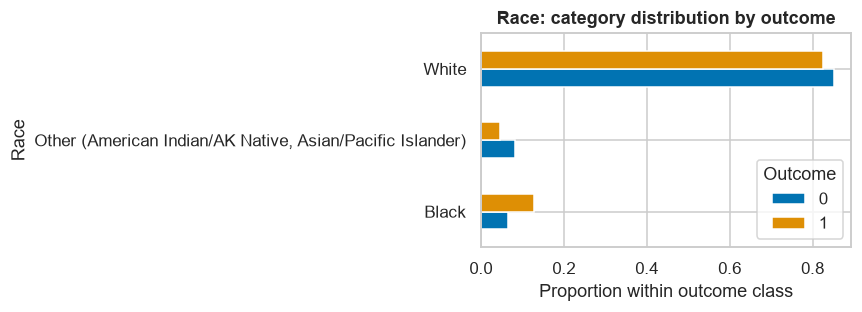


Marital Status: counts and proportions within each outcome class


n      within_class       
_target                            0    1            0      1
Marital Status                                               
Divorced                         349   64        0.124  0.143
Married (including common law)  1865  262        0.661  0.584
Separated                         26   12        0.009  0.027
Single (never married)           427   76        0.151  0.169
Widowed                          154   35        0.055  0.078

Minority categories with fewer than 5 patients: {}


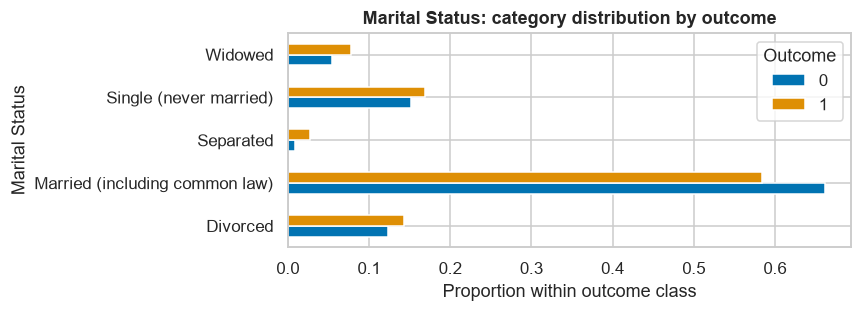


T Stage: counts and proportions within each outcome class


n      within_class       
_target     0    1            0      1
T Stage                               
T1       1180  113        0.418  0.252
T2       1229  218        0.436  0.486
T3        350   90        0.124  0.200
T4         62   28        0.022  0.062

Minority categories with fewer than 5 patients: {}


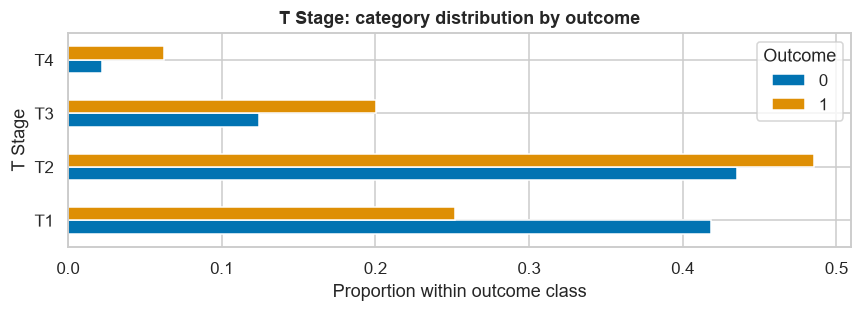


N Stage: counts and proportions within each outcome class


n      within_class       
_target     0    1            0      1
N Stage                               
N1       1989  190        0.705  0.423
N2        557  119        0.197  0.265
N3        275  140        0.097  0.312

Minority categories with fewer than 5 patients: {}


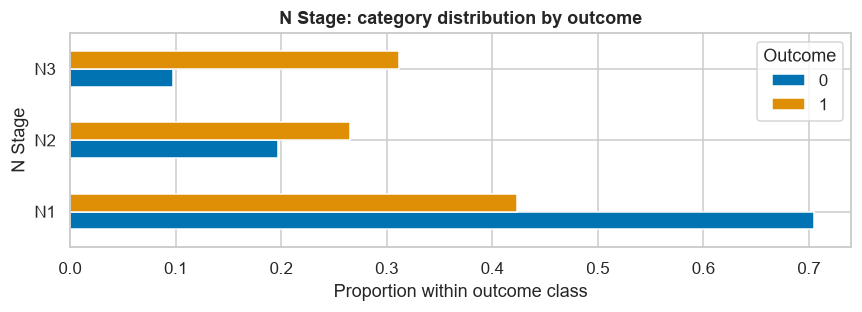


6th Stage: counts and proportions within each outcome class


n      within_class       
_target      0    1            0      1
6th Stage                              
IIA        980   70        0.347  0.156
IIB        802   92        0.284  0.205
IIIA       720  133        0.255  0.296
IIIB        44   14        0.016  0.031
IIIC       275  140        0.097  0.312

Minority categories with fewer than 5 patients: {}


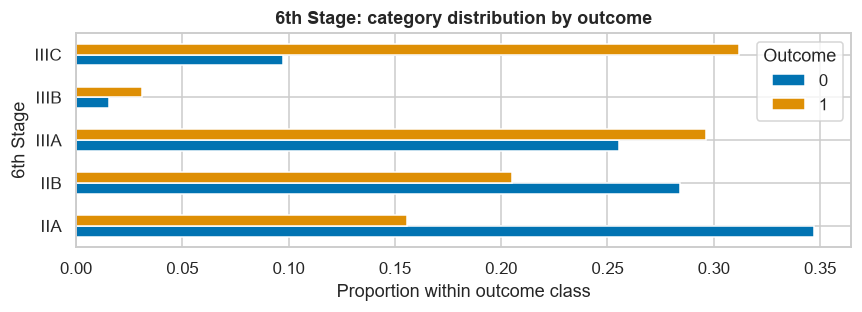


Grade: counts and proportions within each outcome class


n      within_class       
_target                                    0    1            0      1
Grade                                                                
Moderately differentiated; Grade II     1686  216        0.598  0.481
Poorly differentiated; Grade III         731  200        0.259  0.445
Undifferentiated; anaplastic; Grade IV    11    7        0.004  0.016
Well differentiated; Grade I             393   26        0.139  0.058

Minority categories with fewer than 5 patients: {}


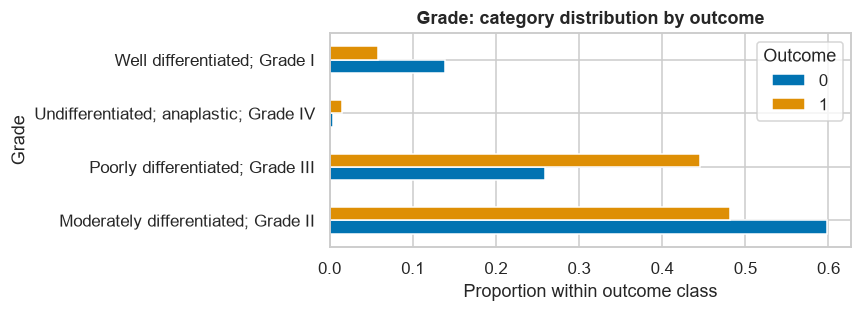


A Stage: counts and proportions within each outcome class


n      within_class       
_target      0    1            0      1
A Stage                                
Distant     48   29        0.017  0.065
Regional  2773  420        0.983  0.935

Minority categories with fewer than 5 patients: {}


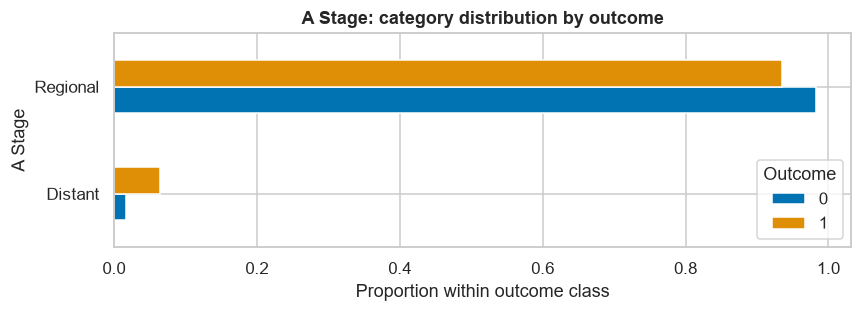


Estrogen Status: counts and proportions within each outcome class


n      within_class       
_target             0    1            0      1
Estrogen Status                               
Negative          149   97        0.053  0.216
Positive         2672  352        0.947  0.784

Minority categories with fewer than 5 patients: {}


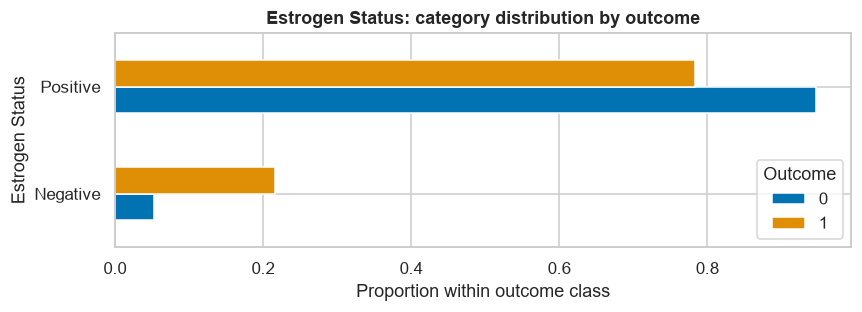


Progesterone Status: counts and proportions within each outcome class


n      within_class       
_target                 0    1            0      1
Progesterone Status                               
Negative              437  177        0.155  0.394
Positive             2384  272        0.845  0.606

Minority categories with fewer than 5 patients: {}


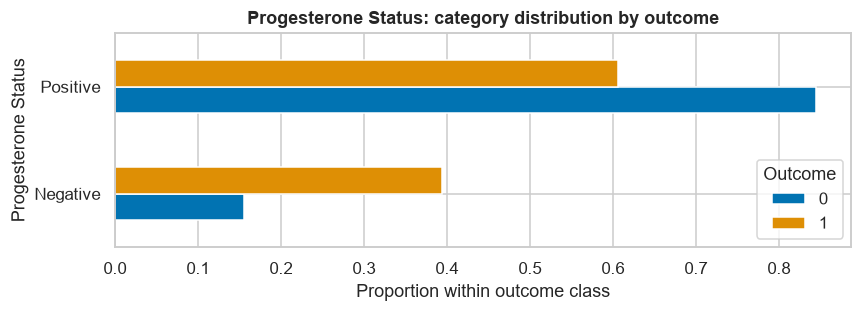

,feature,cramers_v,chi_square_p,minority_rare_levels
0,Race,0.089,0.000,0
1,Marital Status,0.077,0.001,0
2,T Stage,0.145,0.000,0
3,N Stage,0.244,0.000,0
4,6th Stage,0.248,0.000,0
5,Grade,0.162,0.000,0
6,A Stage,0.108,0.000,0
7,Estrogen Status,0.213,0.000,0
8,Progesterone Status,0.211,0.000,0


In [5]:
def cramers_v(table):
    table = np.asarray(table)
    if min(table.shape)<2 or table.sum()==0: return np.nan, np.nan
    chi,p,_,expected=stats.chi2_contingency(table, correction=False)
    n=table.sum(); k=min(table.shape)-1
    return np.sqrt(chi/(n*k)), p

cat_rows=[]
for c in categorical+ordinal:
    tab=pd.crosstab(analysis[c].fillna('[Missing]').astype(str),analysis['_target'])
    prop=tab.div(tab.sum(axis=0),axis=1)
    print(f'\n{c}: counts and proportions within each outcome class')
    display(pd.concat({'n':tab, 'within_class':prop.round(3)},axis=1))
    rare=minor[c].fillna('[Missing]').astype(str).value_counts()
    print('Minority categories with fewer than 5 patients:', rare[rare<5].to_dict())
    v,p=cramers_v(tab); cat_rows.append({'feature':c,'cramers_v':v,'chi_square_p':p,'minority_rare_levels':int((rare<5).sum())})
    if len(tab)<=MAX_CATEGORIES:
        fig,ax=plt.subplots(figsize=(8,max(3,0.38*len(tab))))
        prop.plot.barh(ax=ax); ax.set(title=f'{c}: category distribution by outcome',xlabel='Proportion within outcome class',ylabel=c); ax.legend(title='Outcome'); finish(fig,'category_'+re.sub(r'\W+','_',c))
    else: print('Plot omitted: too many categories; inspect table or refine configuration.')
cat_stats=pd.DataFrame(cat_rows); display(cat_stats.round(3))


## 4. Dependencies and clinical constraints

Pearson measures linear numerical association; Spearman measures monotonic association. For categorical pairs Cramér’s V is nonnegative; for numerical–categorical pairs η (correlation ratio) measures mean separation and is also nonnegative. Values therefore do not encode a common direction across measures. Associations use pairwise complete observations. Ordinal variables are treated as categories: justified ranks, if needed, must be analyzed separately.

Pearson correlations, class 1


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,1.00,-0.12,-0.10,-0.05
Tumor Size,-0.12,1.00,0.09,0.21
Regional Node Examined,-0.10,0.09,1.00,0.58
Reginol Node Positive,-0.05,0.21,0.58,1.00


Spearman correlations, class 1


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,1.00,-0.11,-0.11,-0.08
Tumor Size,-0.11,1.00,0.12,0.29
Regional Node Examined,-0.11,0.12,1.00,0.51
Reginol Node Positive,-0.08,0.29,0.51,1.00


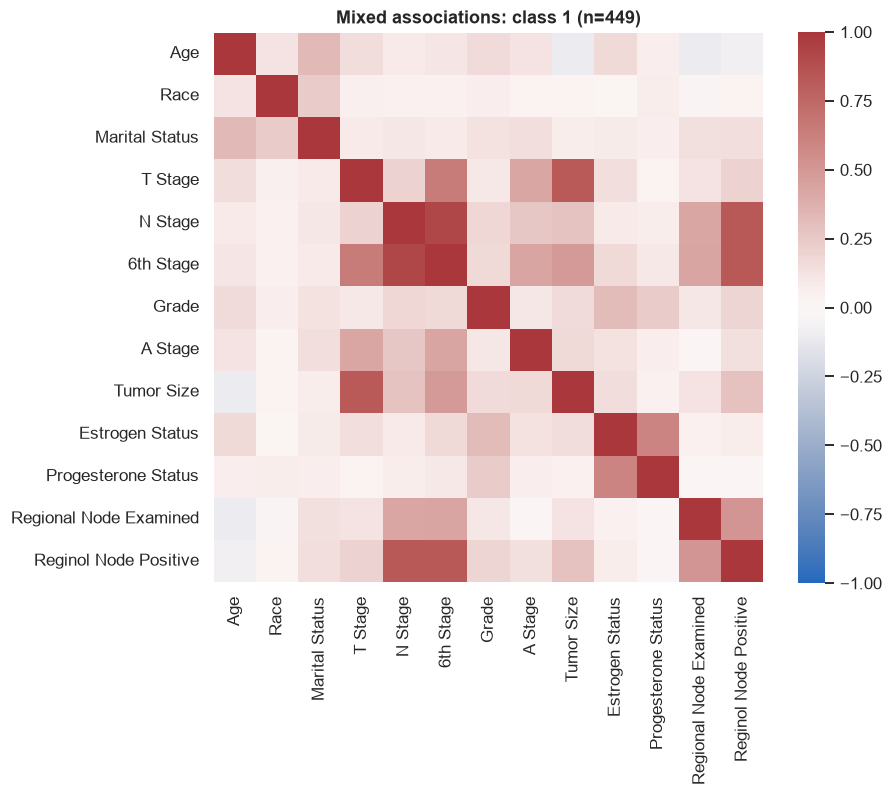

Pearson correlations, class 0


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,1.00,-0.09,-0.01,0.02
Tumor Size,-0.09,1.00,0.11,0.22
Regional Node Examined,-0.01,0.11,1.00,0.38
Reginol Node Positive,0.02,0.22,0.38,1.00


Spearman correlations, class 0


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,1.00,-0.09,-0.01,-0.02
Tumor Size,-0.09,1.00,0.13,0.32
Regional Node Examined,-0.01,0.13,1.00,0.35
Reginol Node Positive,-0.02,0.32,0.35,1.00


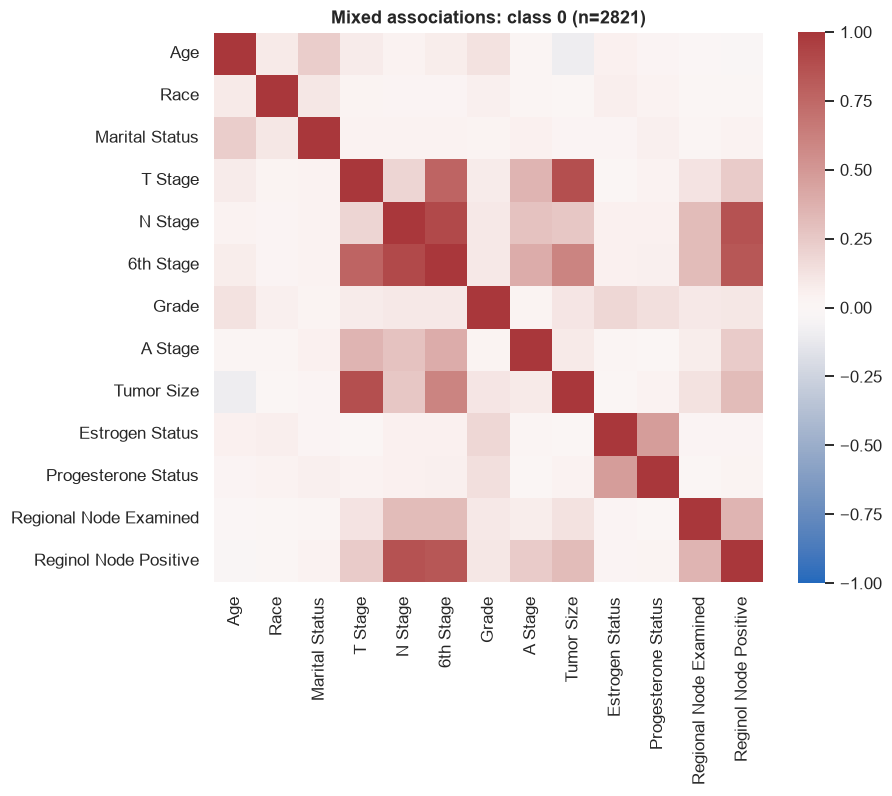

Strong pairwise associations (|measure| ≥ 0.7; unadjusted, not proof of redundancy): [('1', 'T Stage', 'Tumor Size', np.float64(0.823)), ('1', 'N Stage', '6th Stage', np.float64(0.923)), ('1', 'N Stage', 'Reginol Node Positive', np.float64(0.835)), ('1', '6th Stage', 'Reginol Node Positive', np.float64(0.828)), ('0', 'T Stage', '6th Stage', np.float64(0.766)), ('0', 'T Stage', 'Tumor Size', np.float64(0.878)), ('0', 'N Stage', '6th Stage', np.float64(0.91)), ('0', 'N Stage', 'Reginol Node Positive', np.float64(0.86)), ('0', '6th Stage', 'Reginol Node Positive', np.float64(0.842))]


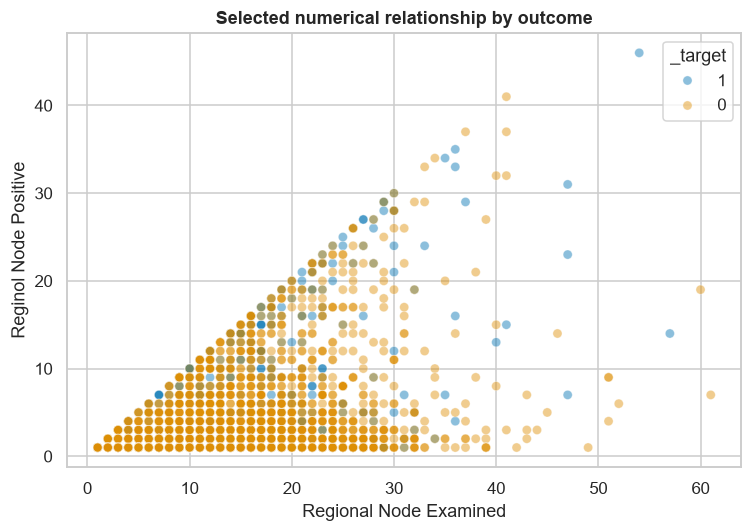

Positive nodes > examined nodes: 0; missing or nonnumeric pairs excluded. Review rather than automatically correct.
Observed staging combinations, minority class (unseen ≠ clinically impossible):


n
T Stage N Stage 6th Stage A Stage     
T2      N1      IIB       Regional  92
T1      N1      IIA       Regional  70
T2      N2      IIIA      Regional  63
        N3      IIIC      Regional  55
T3      N3      IIIC      Regional  34
        N2      IIIA      Regional  28
        N1      IIIA      Regional  22
T1      N3      IIIC      Regional  21
        N2      IIIA      Regional  20
T2      N3      IIIC      Distant    8
T4      N3      IIIC      Regional   8
T3      N3      IIIC      Distant    6
T4      N3      IIIC      Distant    6
        N2      IIIB      Distant    5
        N1      IIIB      Regional   4
        N2      IIIB      Regional   3
T1      N3      IIIC      Distant    2
T4      N1      IIIB      Distant    2

Confirm staging edition, permitted TNM combinations and timing with a domain expert; this frequency table is not a validation rule.


In [6]:
def eta(categories, values):
    t=pd.DataFrame({'cat':categories,'val':values}).dropna()
    if len(t)<3 or t['cat'].nunique()<2 or t['val'].var()==0: return np.nan
    grand=t.val.mean(); groups=t.groupby('cat',observed=True).val
    return np.sqrt(sum(len(g)*(g.mean()-grand)**2 for _,g in groups)/((t.val-grand)**2).sum())

def associations(frame):
    matrix=pd.DataFrame(np.nan,index=features,columns=features)
    for a in features:
        for b in features:
            if a==b: matrix.loc[a,b]=1.; continue
            sub=frame[[a,b]].dropna()
            if len(sub)<3: continue
            if a in numerical and b in numerical: value=sub[a].corr(sub[b],method='spearman')
            elif a not in numerical and b not in numerical: value=cramers_v(pd.crosstab(sub[a],sub[b]))[0]
            else: value=eta(sub[b],sub[a]) if a in numerical else eta(sub[a],sub[b])
            matrix.loc[a,b]=value
    return matrix

assoc_by_class={}
for label in [minority,majority]:
    subset=analysis[analysis['_target']==label]
    assoc=associations(subset); assoc_by_class[label]=assoc
    if numerical:
        print(f'Pearson correlations, class {label}'); display(subset[numerical].corr(method='pearson').round(2))
        print(f'Spearman correlations, class {label}'); display(subset[numerical].corr(method='spearman').round(2))
    if len(features)<=25:
        fig,ax=plt.subplots(figsize=(max(6,len(features)*.65),max(5,len(features)*.55)))
        sns.heatmap(assoc.astype(float),vmin=-1,vmax=1,cmap='vlag',center=0,ax=ax,square=True,annot=len(features)<=12,fmt='.2f')
        ax.set_title(f'Mixed associations: class {label} (n={len(subset)})'); finish(fig,f'associations_{label}')
strong=[]
for label,mat in assoc_by_class.items():
    for i,a in enumerate(features):
        for b in features[i+1:]:
            v=mat.loc[a,b]
            if pd.notna(v) and abs(v)>=.7: strong.append((str(label),a,b,round(v,3)))
print('Strong pairwise associations (|measure| ≥ 0.7; unadjusted, not proof of redundancy):',strong or 'none detected')
if len(numerical)>=2:
    # Select the strongest observed numerical association, rather than producing a full scatterplot matrix.
    corr=analysis[numerical].corr(method='spearman').abs(); pairs=[(corr.loc[a,b],a,b) for i,a in enumerate(numerical) for b in numerical[i+1:] if pd.notna(corr.loc[a,b])]
    if pairs:
        _,a,b=max(pairs); fig,ax=plt.subplots(figsize=(7,5)); sns.scatterplot(data=analysis,x=a,y=b,hue='_target',alpha=.45,ax=ax); ax.set_title('Selected numerical relationship by outcome'); finish(fig,'selected_pair')

lower={c.lower():c for c in df.columns}
examined=next((c for c in df if 'node' in c.lower() and 'examined' in c.lower()),None)
positive=next((c for c in df if 'node' in c.lower() and 'positive' in c.lower()),None)
constraint_count=None
if examined and positive:
    ex=pd.to_numeric(analysis[examined],errors='coerce'); po=pd.to_numeric(analysis[positive],errors='coerce')
    constraint_count=int((po>ex).sum()); print(f'Positive nodes > examined nodes: {constraint_count}; missing or nonnumeric pairs excluded. Review rather than automatically correct.')
stage_cols=[c for c in features if 'stage' in c.lower()]
if len(stage_cols)>=2:
    print('Observed staging combinations, minority class (unseen ≠ clinically impossible):')
    display(minor[stage_cols].fillna('[Missing]').value_counts().head(20).rename('n').to_frame())
    print('Confirm staging edition, permitted TNM combinations and timing with a domain expert; this frequency table is not a validation rule.')


## 5. Representation and fairness audit

Outcome prevalence within a demographic group and the distribution of minority cases across groups have different denominators. Small counts yield unstable estimates; Wilson intervals describe sampling uncertainty only. Dataset representation is not model fairness; fairness metrics require predictions, an appropriate reference group and a stated clinical use. Race categories are social/data-collection constructs and can reflect structural bias.

Age: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation


,Age,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
2,"(50.0, 60.0]",1118,135,0.121,0.301,0.103,0.141,False
1,"(40.0, 50.0]",974,111,0.114,0.247,0.096,0.135,False
3,"(60.0, 70.0]",944,162,0.172,0.361,0.149,0.197,False
0,"(-0.001, 40.0]",234,41,0.175,0.091,0.132,0.229,False


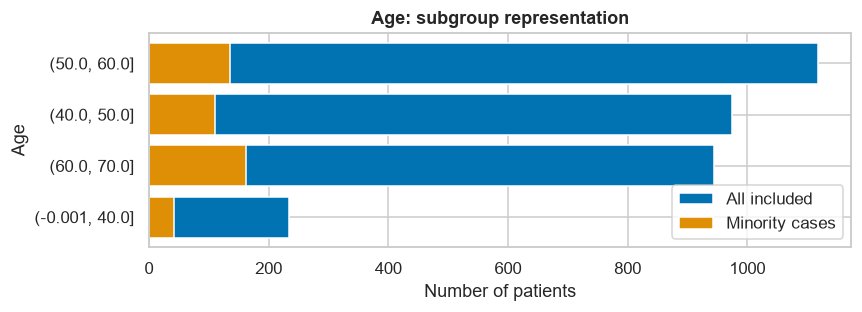

Numerical feature medians by group; descriptive only:


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,,,,
"(-0.001, 40.0]",38.0,29.0,14.0,3.0
"(40.0, 50.0]",47.0,25.0,14.0,2.0
"(50.0, 60.0]",56.0,24.0,14.0,2.0
"(60.0, 70.0]",65.0,22.0,14.0,2.0


Race: distribution within Age groups


Race,Black,"Other (American Indian/AK Native, Asian/Pacific Islander)",White
Age,,,
"(-0.001, 40.0]",0.10,0.14,0.76
"(40.0, 50.0]",0.09,0.09,0.83
"(50.0, 60.0]",0.07,0.08,0.86
"(60.0, 70.0]",0.06,0.06,0.88


Marital Status: distribution within Age groups


Marital Status,Divorced,Married (including common law),Separated,Single (never married),Widowed
Age,,,,,
"(-0.001, 40.0]",0.07,0.66,0.02,0.24,0.01
"(40.0, 50.0]",0.11,0.69,0.02,0.18,0.01
"(50.0, 60.0]",0.15,0.65,0.01,0.15,0.04
"(60.0, 70.0]",0.13,0.61,0.01,0.11,0.13


T Stage: distribution within Age groups


T Stage,T1,T2,T3,T4
Age,,,,
"(-0.001, 40.0]",0.33,0.41,0.23,0.04
"(40.0, 50.0]",0.35,0.47,0.16,0.02
"(50.0, 60.0]",0.42,0.43,0.12,0.03
"(60.0, 70.0]",0.43,0.44,0.11,0.03


Race: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation


,Race,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
2,White,2772,371,0.134,0.826,0.122,0.147,False
1,"Other (American Indian/AK Native, Asian/Pacifi...",255,21,0.082,0.047,0.054,0.123,False
0,Black,243,57,0.235,0.127,0.186,0.292,False


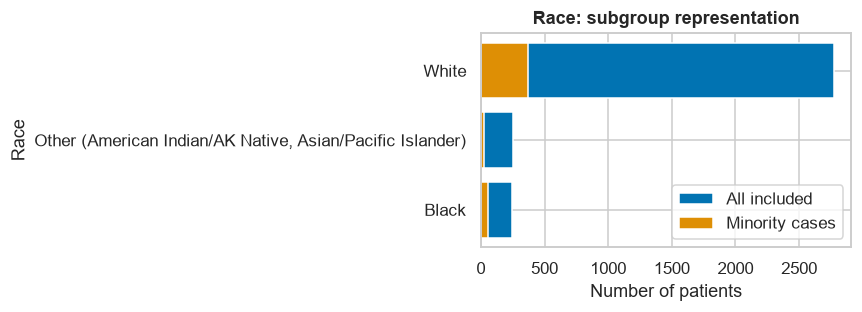

Numerical feature medians by group; descriptive only:


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Race,,,,
Black,53.0,25.0,13.0,3.0
"Other (American Indian/AK Native, Asian/Pacific Islander)",52.0,25.0,14.0,2.0
White,55.0,25.0,14.0,2.0


Marital Status: distribution within Race groups


Marital Status,Divorced,Married (including common law),Separated,Single (never married),Widowed
Race,,,,,
Black,0.15,0.39,0.03,0.34,0.09
"Other (American Indian/AK Native, Asian/Pacific Islander)",0.10,0.72,0.02,0.11,0.05
White,0.13,0.67,0.01,0.14,0.05


T Stage: distribution within Race groups


T Stage,T1,T2,T3,T4
Race,,,,
Black,0.39,0.47,0.11,0.03
"Other (American Indian/AK Native, Asian/Pacific Islander)",0.35,0.51,0.12,0.02
White,0.40,0.43,0.14,0.03


T Stage: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation


,T Stage,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
1,T2,1447,218,0.151,0.486,0.133,0.170,False
0,T1,1293,113,0.087,0.252,0.073,0.104,False
2,T3,440,90,0.205,0.200,0.169,0.245,False
3,T4,90,28,0.311,0.062,0.225,0.413,False


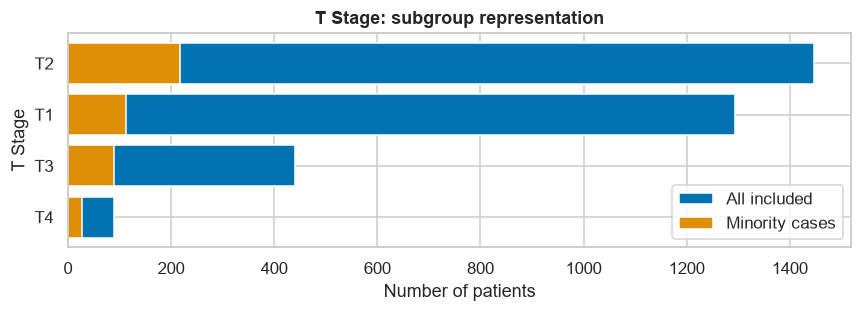

Numerical feature medians by group; descriptive only:


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
T Stage,,,,
T1,55.0,15.0,13.0,1.0
T2,54.0,30.0,14.0,3.0
T3,52.0,65.0,15.0,4.0
T4,55.0,54.5,15.0,6.5


Race: distribution within T Stage groups


Race,Black,"Other (American Indian/AK Native, Asian/Pacific Islander)",White
T Stage,,,
T1,0.07,0.07,0.86
T2,0.08,0.09,0.83
T3,0.06,0.07,0.87
T4,0.09,0.04,0.87


Marital Status: distribution within T Stage groups


Marital Status,Divorced,Married (including common law),Separated,Single (never married),Widowed
T Stage,,,,,
T1,0.12,0.67,0.01,0.14,0.06
T2,0.13,0.63,0.01,0.16,0.06
T3,0.12,0.68,0.00,0.14,0.06
T4,0.18,0.53,0.02,0.23,0.03


N Stage: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation


,N Stage,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
0,N1,2179,190,0.087,0.423,0.076,0.100,False
1,N2,676,119,0.176,0.265,0.149,0.207,False
2,N3,415,140,0.337,0.312,0.294,0.384,False


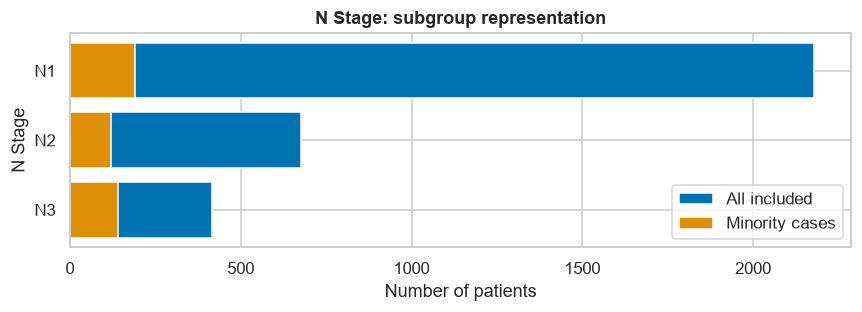

Numerical feature medians by group; descriptive only:


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
N Stage,,,,
N1,54.0,21.0,13.0,1.0
N2,54.0,30.0,15.0,5.0
N3,55.0,37.0,19.0,14.0


Race: distribution within N Stage groups


Race,Black,"Other (American Indian/AK Native, Asian/Pacific Islander)",White
N Stage,,,
N1,0.07,0.08,0.85
N2,0.08,0.08,0.83
N3,0.10,0.06,0.84


Marital Status: distribution within N Stage groups


Marital Status,Divorced,Married (including common law),Separated,Single (never married),Widowed
N Stage,,,,,
N1,0.12,0.66,0.01,0.15,0.05
N2,0.12,0.64,0.01,0.17,0.05
N3,0.15,0.60,0.02,0.14,0.09


T Stage: distribution within N Stage groups


T Stage,T1,T2,T3,T4
N Stage,,,,
N1,0.48,0.41,0.10,0.01
N2,0.25,0.52,0.18,0.05
N3,0.18,0.48,0.26,0.08


6th Stage: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation


,6th Stage,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
0,IIA,1050,70,0.067,0.156,0.053,0.083,False
1,IIB,894,92,0.103,0.205,0.085,0.125,False
2,IIIA,853,133,0.156,0.296,0.133,0.182,False
4,IIIC,415,140,0.337,0.312,0.294,0.384,False
3,IIIB,58,14,0.241,0.031,0.150,0.365,True


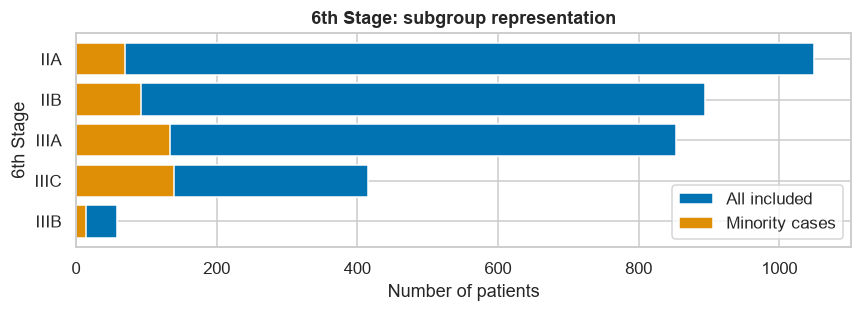

Numerical feature medians by group; descriptive only:


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
6th Stage,,,,
IIA,55.0,15.0,12.0,1.0
IIB,54.0,30.0,13.0,2.0
IIIA,54.0,36.0,14.0,5.0
IIIB,55.5,51.5,12.0,4.5
IIIC,55.0,37.0,19.0,14.0


Race: distribution within 6th Stage groups


Race,Black,"Other (American Indian/AK Native, Asian/Pacific Islander)",White
6th Stage,,,
IIA,0.07,0.07,0.86
IIB,0.07,0.09,0.84
IIIA,0.07,0.09,0.84
IIIB,0.09,0.07,0.84
IIIC,0.10,0.06,0.84


Marital Status: distribution within 6th Stage groups


Marital Status,Divorced,Married (including common law),Separated,Single (never married),Widowed
6th Stage,,,,,
IIA,0.12,0.67,0.01,0.15,0.06
IIB,0.13,0.64,0.01,0.16,0.05
IIIA,0.12,0.66,0.01,0.16,0.05
IIIB,0.17,0.60,0.00,0.21,0.02
IIIC,0.15,0.60,0.02,0.14,0.09


T Stage: distribution within 6th Stage groups


T Stage,T1,T2,T3,T4
6th Stage,,,,
IIA,1.00,0.00,0.00,0.00
IIB,0.00,1.00,0.00,0.00
IIIA,0.20,0.41,0.39,0.00
IIIB,0.00,0.00,0.00,1.00
IIIC,0.18,0.48,0.26,0.08


A Stage: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation


,A Stage,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
1,Regional,3193,420,0.132,0.935,0.120,0.144,False
0,Distant,77,29,0.377,0.065,0.277,0.488,False


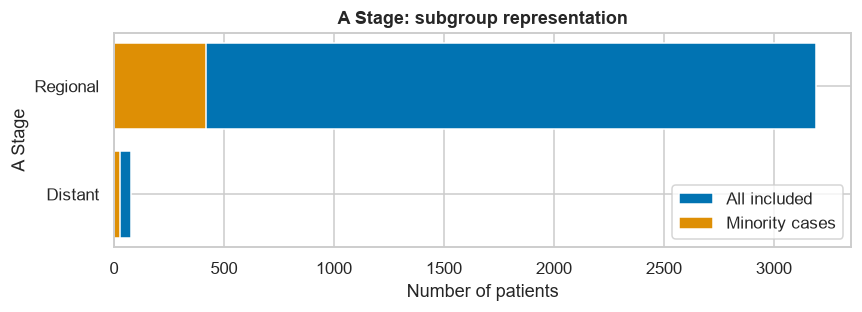

Numerical feature medians by group; descriptive only:


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
A Stage,,,,
Distant,53.0,40.0,17.0,12.0
Regional,55.0,25.0,14.0,2.0


Race: distribution within A Stage groups


Race,Black,"Other (American Indian/AK Native, Asian/Pacific Islander)",White
A Stage,,,
Distant,0.09,0.05,0.86
Regional,0.07,0.08,0.85


Marital Status: distribution within A Stage groups


Marital Status,Divorced,Married (including common law),Separated,Single (never married),Widowed
A Stage,,,,,
Distant,0.19,0.55,0.04,0.18,0.04
Regional,0.12,0.65,0.01,0.15,0.06


T Stage: distribution within A Stage groups


T Stage,T1,T2,T3,T4
A Stage,,,,
Distant,0.08,0.34,0.16,0.43
Regional,0.40,0.45,0.13,0.02


Intersection: ['Age', 'Race']


,Age,Race,n,minority_n,minority_prevalence,share_of_minority,wilson_low,wilson_high,small_group
8,"(50.0, 60.0]",White,957,113,0.118,0.252,0.099,0.140,False
11,"(60.0, 70.0]",White,830,139,0.167,0.310,0.144,0.194,False
5,"(40.0, 50.0]",White,807,91,0.113,0.203,0.093,0.136,False
2,"(-0.001, 40.0]",White,178,28,0.157,0.062,0.111,0.218,False
7,"(50.0, 60.0]","Other (American Indian/AK Native, Asian/Pacifi...",85,7,0.082,0.016,0.040,0.160,True
3,"(40.0, 50.0]",Black,84,15,0.179,0.033,0.111,0.274,True
4,"(40.0, 50.0]","Other (American Indian/AK Native, Asian/Pacifi...",83,5,0.060,0.011,0.026,0.133,True
6,"(50.0, 60.0]",Black,76,15,0.197,0.033,0.123,0.300,True
9,"(60.0, 70.0]",Black,59,18,0.305,0.040,0.203,0.431,True
10,"(60.0, 70.0]","Other (American Indian/AK Native, Asian/Pacifi...",55,5,0.091,0.011,0.039,0.196,True


Groups flagged small should not be interpreted as reliable estimates or as adequate support for synthetic generation.


In [7]:
def wilson(k,n,z=1.96):
    if not n: return (np.nan,np.nan)
    p=k/n; d=1+z*z/n; center=(p+z*z/(2*n))/d; half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return center-half,center+half

if DEMOGRAPHIC_COLUMNS is None:
    demo=[c for c in df if re.search(r'age|race|ethnic|sex|gender',c,re.I)]
else: demo=[c for c in DEMOGRAPHIC_COLUMNS if c in df]
audit=pd.DataFrame(index=analysis.index)
for c in demo:
    if 'age' in c.lower() and pd.to_numeric(analysis[c],errors='coerce').notna().any():
        audit[c]=pd.cut(pd.to_numeric(analysis[c],errors='coerce'),AGE_BINS,include_lowest=True).astype('string').fillna('[Missing/out of range]')
    else: audit[c]=analysis[c].astype('string').fillna('[Missing]')
def subgroup_summary(keys):
    temp=audit[keys].copy(); temp['_minor']=(analysis['_target']==minority).astype(int)
    result=temp.groupby(keys,dropna=False,observed=True)['_minor'].agg(n='size',minority_n='sum').reset_index()
    result['minority_prevalence']=result.minority_n/result.n
    result['share_of_minority']=result.minority_n/counts[minority]
    intervals=result.apply(lambda r:wilson(r.minority_n,r.n),axis=1)
    result['wilson_low']=[v[0] for v in intervals]; result['wilson_high']=[v[1] for v in intervals]
    result['small_group']=(result.n<MIN_GROUP_N)|(result.minority_n<MIN_MINORITY_GROUP_N)
    return result.sort_values('n',ascending=False)
subgroups={}
if not demo: print('No configured demographic attributes found; fairness analysis is limited.')
for c in demo:
    table=subgroup_summary([c]); subgroups[c]=table
    print(f'{c}: subgroup counts, outcome prevalence, Wilson 95% intervals, minority representation'); display(table.round(3))
    if len(table)<=MAX_CATEGORIES:
        fig,ax=plt.subplots(figsize=(8,max(3,.4*len(table))))
        plot=table.iloc[::-1]; ax.barh(plot[c].astype(str),plot['n'],label='All included'); ax.barh(plot[c].astype(str),plot['minority_n'],label='Minority cases'); ax.set(title=f'{c}: subgroup representation',xlabel='Number of patients',ylabel=c); ax.legend(); finish(fig,'demographic_'+re.sub(r'\W+','_',c))
    if numerical:
        med=analysis[numerical].groupby(audit[c],observed=True).median()
        print('Numerical feature medians by group; descriptive only:'); display(med.round(2))
    for f in (categorical+ordinal)[:3]:
        if f != c and analysis[f].nunique()<=MAX_CATEGORIES:
            print(f'{f}: distribution within {c} groups'); display(pd.crosstab(audit[c],analysis[f],normalize='index').round(2))
intersection=None
if len(demo)>=2:
    intersection=subgroup_summary(demo[:2]); print(f'Intersection: {demo[:2]}'); display(intersection.round(3))
    print('Groups flagged small should not be interpreted as reliable estimates or as adequate support for synthetic generation.')


## 6. Method selection framework

| Method | Types and marginals | Dependencies and limitations | Interpretability and sample needs |
|---|---|---|---|
| Multivariate Gaussian | Continuous, roughly Gaussian marginals; no direct categorical support | Linear covariance; may yield negative values, impossible categories and stage combinations | Transparent but sensitive to outliers, small samples, singular covariance |
| Gaussian mixture | Continuous, can model multimodality | Mixture correlations; component selection may overfit small or sparse subgroups; constraints remain unsolved | Moderately interpretable; components need enough data |
| Gaussian copula | Flexible marginal models and mixed-data extensions | Latent Gaussian dependence misses some nonlinear/tail structure; discrete ties and constraints need care | Marginals are inspectable; verify support and fitting stability |
| SMOTE / SMOTENC | Continuous / mixed nominal-continuous; encoding and scaling matter | Local interpolation can cross boundaries or make implausible combinations; SMOTENC does not inherently respect clinical ordinal rules | Simple local mechanism; rare subgroups may lack neighbors |
| Conditional tabular models | Can handle mixed variables and conditional categories, depending on implementation | Flexible but can memorize, ignore constraints or distort sparse subgroup relationships | Often less transparent; data-hungry, require privacy and utility audits |

None guarantees fairness or valid records. Begin with an unresampled baseline and class weighting; compare several sampling ratios rather than assuming 1:1. Small n is context-dependent; no universal cutoff makes a generator safe.

## 7. Automatically generated evidence-based report

The report summarizes the observed full dataset. Interpret method choices as provisional hypotheses that require training-only validation, external validation where feasible, subgroup uncertainty and clinical review.

In [8]:
lines=['# Synthetic data feasibility report', '', f'**Source:** {DATA_PATH}; **rows:** {len(df)}; **included:** {len(analysis)}; **outcome:** {outcome_name}.',
       f'**Classes:** {counts.to_dict()}; minority = {minority}; majority/minority ratio = {counts.iloc[0]/counts.iloc[1]:.2f}.', '', '## Dataset Quality']
lines += [f'- {int(df.duplicated().sum())} exact duplicate input rows; {len(empty_cols)} all-missing columns; {int(censored.sum())} alive patients with follow-up <60 months excluded under the five-year protocol.' if TARGET_MODE=='five_year' else f'- {int(df.duplicated().sum())} exact duplicate input rows; target is a raw column, so a five-year interpretation and censoring are unverified.',
          f'- Features selected ({len(features)}): {", ".join(features)}. Excluded outcome/follow-up columns: {", ".join(sorted(set(df.columns)-set(features)))}.',
          f'- Missingness: {", ".join(f"{c} {quality.loc[c, chr(109)+chr(105)+chr(115)+chr(115)+chr(105)+chr(110)+chr(103)+chr(95)+chr(112)+chr(99)+chr(116)]:.1f}%" for c in quality.index if quality.loc[c,"missing_pct"]>0) or "none among selected features"}. Check provenance, outcome coding, date of prediction and clinical plausibility; pattern and domain checks are not exhaustive.', '', '## Minority-Class Characteristics']
if not num_stats.empty:
    for _,r in num_stats.iterrows():
        label='normality test unavailable' if pd.isna(r.normality_p) else ('normality rejected at unadjusted 0.05' if r.normality_p<.05 else 'normality not rejected; not evidence of Gaussianity')
        lines.append(f'- {r.feature}: n={int(r.n)}, median={r["median"]:.2f}, skew={r["skew"]:.2f}, IQR flags={r.IQR_flags}; {label}; minority vs majority rank-biserial={r.rank_biserial:.2f}. Inspect plots and multimodality.')
else: lines.append('- No numerical feature was available for distributional analysis.')
if not cat_stats.empty:
    rare=cat_stats[cat_stats.minority_rare_levels>0]
    lines.append('- Categorical features with minority levels below 5 observations: '+ (', '.join(rare.feature) if len(rare) else 'none observed')+'.')
lines += ['', '## Feature Dependencies', '- Strong observed associations: '+ ('; '.join(f'class {a}: {b}–{c} ({v})' for a,b,c,v in strong[:12]) if strong else 'none reached the exploratory |0.7| threshold')+'. These measures use different scales and do not demonstrate causal or redundant features.',
          '- '+(f'Positive nodes exceeded examined nodes in {constraint_count} included records.' if constraint_count is not None else 'Node-count constraint unavailable for this dataset.')+' Stage compatibility requires a verified staging-edition rule and expert review.', '', '## Fairness Considerations']
if subgroups:
    for c,t in subgroups.items():
        small=t[t.small_group]
        lines.append(f'- {c}: {len(t)} groups; {len(small)} flagged below n={MIN_GROUP_N} total or n={MIN_MINORITY_GROUP_N} minority; flagged: '+(', '.join(small[c].astype(str)) if len(small) else 'none')+'. Thresholds are screening heuristics, not adequacy guarantees.')
else: lines.append('- No configured demographic columns were found; representation cannot be assessed.')
if intersection is not None: lines.append(f'- Intersection {demo[:2]}: {int(intersection.small_group.sum())} of {len(intersection)} groups flagged as small.')
lines += ['- Representation, observed outcome prevalence and predictive fairness are distinct; selection bias, censoring and historical care inequities may affect all three.', '', '## Synthetic Data Feasibility']
mixed=bool(categorical or ordinal)
lines.append(f'- Observed feature types: {len(numerical)} numerical, {len(categorical)} categorical, {len(ordinal)} explicitly ordinal; minority n={len(minor)}.')
lines.append('- Multivariate Gaussian and ordinary GMM cannot directly generate valid mixed-type records; do not use them naively.' if mixed else '- Gaussian/GMM require verified continuous support, joint dependence and adequate sample size; inspect distributions and constraints before considering them.')
lines.append('- Consider a mixed-data copula or conditional tabular model only with validated marginals, dependencies and clinical constraints; their fit and rare-group behavior cannot be inferred from EDA alone.')
lines.append('- Consider SMOTENC for mixed data or SMOTE for continuous-only data as experimental training-fold baselines; encoding, neighborhood support and valid clinical combinations require explicit review. Class weighting is the simpler starting point.')
lines += ['', '## Recommended Next Steps', '- Define prediction time, confirm outcome coding and prespecify patient-level or external/temporal split where applicable. Reserve test data for final evaluation; redo EDA and all model selection within training data.', '- Compare no resampling, class weighting, and selected sampling ratios using suitable training-fold-only pipelines. Compare only feasible mixed-data generators; do not force 1:1.', '- Evaluate PR-AUC, sensitivity, specificity, calibration and uncertainty; audit subgroup sample sizes, calibration, error rates and intersectional uncertainty, along with XAI stability.', '- For any generator, check conditional and joint distributions, constraints, near-duplicates, privacy/memorization and downstream utility on real untouched data. Synthetic observations are not independent clinical evidence.']
report='\n'.join(lines)
display(Markdown(report))
if SAVE_OUTPUTS:
    (OUTPUT_DIR/'feasibility_report.md').write_text(report,encoding='utf-8')
    print('Saved report to', OUTPUT_DIR.resolve())


# Synthetic data feasibility report

**Source:** C:\Users\Tommaso\Code\progetto\Copia di SEER Breast Cancer Dataset .csv; **rows:** 4024; **included:** 3270; **outcome:** Death before 60 months (1) vs survival to 60 months (0).
**Classes:** {'0': 2821, '1': 449}; minority = 1; majority/minority ratio = 6.28.

## Dataset Quality
- 1 exact duplicate input rows; 1 all-missing columns; 754 alive patients with follow-up <60 months excluded under the five-year protocol.
- Features selected (13): Age, Race, Marital Status, T Stage, N Stage, 6th Stage, Grade, A Stage, Tumor Size, Estrogen Status, Progesterone Status, Regional Node Examined, Reginol Node Positive. Excluded outcome/follow-up columns: Status, Survival Months, Unnamed: 3.
- Missingness: none among selected features. Check provenance, outcome coding, date of prediction and clinical plausibility; pattern and domain checks are not exhaustive.

## Minority-Class Characteristics
- Age: n=449, median=56.00, skew=-0.41, IQR flags=0; normality rejected at unadjusted 0.05; minority vs majority rank-biserial=0.09. Inspect plots and multimodality.
- Tumor Size: n=449, median=30.00, skew=1.36, IQR flags=16; normality rejected at unadjusted 0.05; minority vs majority rank-biserial=0.25. Inspect plots and multimodality.
- Regional Node Examined: n=449, median=14.00, skew=1.02, IQR flags=8; normality rejected at unadjusted 0.05; minority vs majority rank-biserial=0.06. Inspect plots and multimodality.
- Reginol Node Positive: n=449, median=5.00, skew=1.56, IQR flags=18; normality rejected at unadjusted 0.05; minority vs majority rank-biserial=0.33. Inspect plots and multimodality.
- Categorical features with minority levels below 5 observations: none observed.

## Feature Dependencies
- Strong observed associations: class 1: T Stage–Tumor Size (0.823); class 1: N Stage–6th Stage (0.923); class 1: N Stage–Reginol Node Positive (0.835); class 1: 6th Stage–Reginol Node Positive (0.828); class 0: T Stage–6th Stage (0.766); class 0: T Stage–Tumor Size (0.878); class 0: N Stage–6th Stage (0.91); class 0: N Stage–Reginol Node Positive (0.86); class 0: 6th Stage–Reginol Node Positive (0.842). These measures use different scales and do not demonstrate causal or redundant features.
- Positive nodes exceeded examined nodes in 0 included records. Stage compatibility requires a verified staging-edition rule and expert review.

## Fairness Considerations
- Age: 4 groups; 0 flagged below n=30 total or n=20 minority; flagged: none. Thresholds are screening heuristics, not adequacy guarantees.
- Race: 3 groups; 0 flagged below n=30 total or n=20 minority; flagged: none. Thresholds are screening heuristics, not adequacy guarantees.
- T Stage: 4 groups; 0 flagged below n=30 total or n=20 minority; flagged: none. Thresholds are screening heuristics, not adequacy guarantees.
- N Stage: 3 groups; 0 flagged below n=30 total or n=20 minority; flagged: none. Thresholds are screening heuristics, not adequacy guarantees.
- 6th Stage: 5 groups; 1 flagged below n=30 total or n=20 minority; flagged: IIIB. Thresholds are screening heuristics, not adequacy guarantees.
- A Stage: 2 groups; 0 flagged below n=30 total or n=20 minority; flagged: none. Thresholds are screening heuristics, not adequacy guarantees.
- Intersection ['Age', 'Race']: 8 of 12 groups flagged as small.
- Representation, observed outcome prevalence and predictive fairness are distinct; selection bias, censoring and historical care inequities may affect all three.

## Synthetic Data Feasibility
- Observed feature types: 4 numerical, 9 categorical, 0 explicitly ordinal; minority n=449.
- Multivariate Gaussian and ordinary GMM cannot directly generate valid mixed-type records; do not use them naively.
- Consider a mixed-data copula or conditional tabular model only with validated marginals, dependencies and clinical constraints; their fit and rare-group behavior cannot be inferred from EDA alone.
- Consider SMOTENC for mixed data or SMOTE for continuous-only data as experimental training-fold baselines; encoding, neighborhood support and valid clinical combinations require explicit review. Class weighting is the simpler starting point.

## Recommended Next Steps
- Define prediction time, confirm outcome coding and prespecify patient-level or external/temporal split where applicable. Reserve test data for final evaluation; redo EDA and all model selection within training data.
- Compare no resampling, class weighting, and selected sampling ratios using suitable training-fold-only pipelines. Compare only feasible mixed-data generators; do not force 1:1.
- Evaluate PR-AUC, sensitivity, specificity, calibration and uncertainty; audit subgroup sample sizes, calibration, error rates and intersectional uncertainty, along with XAI stability.
- For any generator, check conditional and joint distributions, constraints, near-duplicates, privacy/memorization and downstream utility on real untouched data. Synthetic observations are not independent clinical evidence.